# Una primera corrida del motor del chancador en el cono secundario de referencia

**Pregunta:** ¿Qué tamaño de producto, capacidad y potencia entrega un cono secundario en el punto de operación de referencia S01, y qué tan lejos queda el mismo motor de un muestreo medido en planta?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** ninguno, este es el notebook de entrada
- **Tiempo de lectura:** unos 25 minutos

## Objetivos

Al terminar este notebook usted puede:

- describir un punto de operación de un chancador con los ocho números que pide el estudio, y decir qué controla cada uno;
- correr una vez el motor del producto y leer el tamaño de producto P80, la capacidad en toneladas por hora y la potencia en kilowatts;
- leer la malla de tamices en la que viven todas las distribuciones de tamaño del motor;
- cargar la tabla de diez muestreos medidos de un cono industrial, correr el motor en uno de ellos y ver cuánto se aleja un número del modelo de un número de planta.

## Preparación

Cada notebook del conjunto está fijado en `notebooks/requirements.txt` y corre en el entorno `.venv-notebooks` que construye `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Este notebook necesita numpy para los arreglos y matplotlib para las figuras:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

ChancaDEM no publica un paquete propio: su motor es la carpeta `data-pipeline/pipeline/model/crusher/`, de modo que la celda siguiente la importa por su ruta, como lo hace cada notebook de este conjunto. La celda además imprime las versiones de las dos bibliotecas.

In [1]:
# Imprima las versiones de las herramientas de este notebook, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

for name in ('numpy', 'matplotlib'):
    print(name, md.version(name))

# El notebook está tres carpetas bajo la raíz del repositorio; el pipeline se importa por su ruta
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.model.crusher import evaluate, Operating, operating_from_survey, grid_edges, grid_mid
from pipeline.hp500.surveys import read_surveys
plt.rcParams.update({"figure.figsize": (7.4, 3.9), "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})

numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos fuentes, ambas versionadas en el repositorio.

- El caso de referencia S01, un punto de operación sintético de cono secundario escrito para el estudio. Propietario: este repositorio, https://github.com/fsantibanezleal/CAOS_ChancaDEM. Clase de licencia: MIT; los artefactos versionados los escribe el pipeline a partir de los parámetros de cada caso. Archivo leído: `data/derived/manifests/S01.json`, cuyo bloque `params` contiene el punto de operación.
- Los diez muestreos de un cono secundario Metso HP500 en la operación de mineral de hierro Minas Rio. Propietario: Rocha, Campos, Silva y Tavares (2024), Minerals 14(9), 919, https://doi.org/10.3390/min14090919. Clase de licencia: CC BY 4.0 (acceso abierto, atribución), véase `conventions/third-party-datasets.md`; las diez filas de muestreos se transcriben de la Tabla A1 del artículo. Archivo leído: `data/examples/hp500-surveys.csv`, leído con el lector de muestreos del pipeline, que interpreta cada celda y rechaza una fila con su motivo en lugar de forzarla.

La celda siguiente lee el manifiesto de S01 e imprime su punto de operación. Un archivo ausente detiene el notebook con su ruta en el error.

In [2]:
# Lea el manifiesto del caso de referencia y conserve su bloque de parámetros
manifest = json.loads((ROOT / "data" / "derived" / "manifests" / "S01.json").read_text(encoding="utf-8"))
params = manifest["params"]
for key, value in params.items():
    print(f"{key:12s} {value}")

machine      cone-sec
css_mm       32.0
throw_mm     30.0
speed_rpm    360.0
feed_x63_mm  90.0
feed_m       1.2
ore_axb      55.0
ore_wi       14.0
calibrated   False


## Método

**Paso 1, el punto de operación.** El motor recibe un registro `Operating`. Tres números definen la máquina: la abertura de lado cerrado CSS (la separación más estrecha entre el manto y la taza, en mm), la excentricidad o carrera (de modo que la abertura de lado abierto es OSS = CSS + carrera) y la velocidad en rev/min. Dos números describen la alimentación como una distribución de Rosin-Rammler (Rosin y Rammler, 1933; https://cir.nii.ac.jp/crid/1572543024341127296): el tamaño característico x63 bajo el cual pasa 63,2 por ciento de la masa y el exponente de uniformidad m. Dos números describen el mineral: la competencia de caída de peso JKMRC A*b (menor es más duro) y el índice de trabajo de Bond Wi en kWh/t. El último campo, `calibrated`, activa el ajuste del HP500 y es False en los casos sintéticos.

La celda construye el registro desde el manifiesto.

In [3]:
# Construya el punto de operación; el registro es inmutable, así que una corrida nunca lo modifica
op = Operating(**params)
print(op)
print("abertura de lado abierto OSS [mm]:", op.css_mm + op.throw_mm)

Operating(machine='cone-sec', css_mm=32.0, throw_mm=30.0, speed_rpm=360.0, feed_x63_mm=90.0, feed_m=1.2, ore_axb=55.0, ore_wi=14.0, calibrated=False)
abertura de lado abierto OSS [mm]: 62.0


**Paso 2, una evaluación.** `evaluate` corre toda la cadena del motor sobre el registro: discretiza la alimentación en la malla de tamices, construye las funciones de clasificación y de quiebre, resuelve el balance poblacional de Whiten para el producto (Whiten, 1972; https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf) y luego lee la capacidad y la potencia. El resultado contiene las distribuciones completas y un conjunto de lecturas escalares, que la celda imprime. F80 y P80 son los tamaños que pasa el 80 por ciento de la alimentación y del producto, y la razón de reducción es F80 sobre P80 (Napier-Munn et al., 1996; https://search.worldcat.org/title/37081193).

In [4]:
# Corra el motor una vez e imprima las lecturas escalares
result = evaluate(op)
print(f"F80 = {result.f80:.2f} mm")
print(f"P80 = {result.p80:.2f} mm")
print("razón de reducción", f"= {result.reduction_ratio:.2f}")
print("capacidad", f"= {result.throughput_tph:.0f} t/h")
print("potencia", f"= {result.power_kw:.0f} kW")
print("régimen", result.regime, "| válido", result.valid)

F80 = 126.03 mm
P80 = 27.70 mm
razón de reducción = 4.55
capacidad = 643 t/h
potencia = 287 kW
régimen choke | válido True


**Paso 3, la malla de tamices.** Cada distribución del motor vive en una sola malla fija de 28 clases de tamaño, desde un tamaño máximo de 256 mm hacia abajo en un factor de raíz de dos por clase, la serie estándar de tamices de laboratorio. Los bordes descienden de grueso a fino; el tamaño medio de una clase es la media geométrica de sus dos bordes. La celda imprime los extremos de la malla y la masa de la alimentación y del producto en las clases cercanas al P80 del producto, para ver hacia dónde mueve la masa el chancador.

In [5]:
# Muestre los extremos de la malla y la masa por clase de la alimentación y el producto cerca del P80
edges, mids = grid_edges(), grid_mid()
print("clases:", len(mids), "| borde superior", round(edges[0], 1), "mm", "| borde inferior", round(edges[-1], 4), "mm")
near = [i for i, m in enumerate(mids) if 8 <= m <= 70]
print("tamaño medio [mm]   masa alimentación   masa producto")
for i in near:
    print(f"{mids[i]:10.2f} {result.feed.mass[i]:12.4f} {result.product.mass[i]:12.4f}")

clases: 28 | borde superior 256.0 mm | borde inferior 0.0156 mm
tamaño medio [mm]   masa alimentación   masa producto
     53.82       0.1346       0.0217
     38.05       0.1070       0.1094
     26.91       0.0798       0.1653
     19.03       0.0571       0.1246
     13.45       0.0398       0.0976
      9.51       0.0272       0.0780


La tabla muestra el trabajo del chancador de un vistazo: la clase de unos 54 mm contiene 13,5 por ciento de la alimentación y solo 2,2 por ciento del producto, y la masa del producto alcanza su máximo en la clase de unos 27 mm con 16,5 por ciento. La figura siguiente dibuja la misma información como curvas de pasante acumulado en un eje de tamaños logarítmico, como lee un análisis granulométrico un metalurgista de planta, con F80 y P80 marcados.

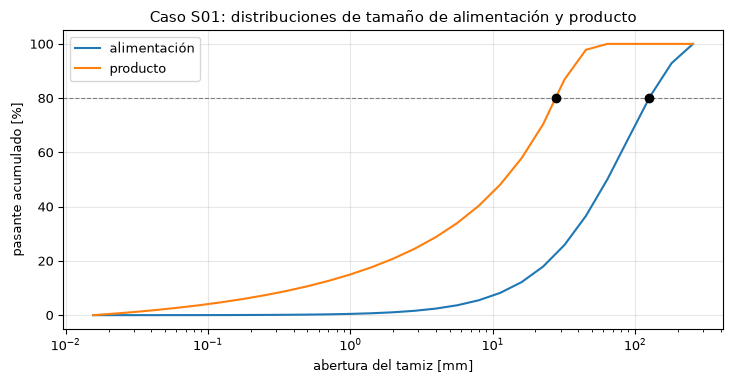

In [6]:
# Grafique el pasante acumulado de la alimentación y el producto de S01 y marque F80 y P80
fig, ax = plt.subplots()
ax.plot(edges, np.array(result.feed.passing) * 100, label="alimentación")
ax.plot(edges, np.array(result.product.passing) * 100, label="producto")
ax.axhline(80, color="grey", lw=0.8, ls="--")
ax.plot([result.f80, result.p80], [80, 80], "ko")
ax.set_xscale("log")
ax.set_xlabel("abertura del tamiz [mm]")
ax.set_ylabel("pasante acumulado [%]")
ax.set_title("Caso S01: distribuciones de tamaño de alimentación y producto")
ax.legend()
fig.tight_layout()
plt.show()

Las dos curvas son una alimentación de Rosin-Rammler y el producto que el cálculo de Whiten deriva de ella. La línea horizontal punteada es el nivel de 80 por ciento donde se leen F80 y P80; la distancia entre los dos puntos negros es la reducción de tamaño que logró la máquina con esta abertura. Lo que la figura no muestra es por qué el producto tiene esa forma. Para eso hacen falta las funciones de quiebre y de clasificación, que el tema 03 abre una por una.

**Paso 4, un muestreo de planta.** La segunda vía del estudio son datos reales. El lector de muestreos interpreta el CSV de los diez muestreos del HP500 celda por celda, con una verificación de límites por columna, y entrega las filas aceptadas y las rechazadas con su motivo. La celda imprime ambos conteos y el primer muestreo. Cada muestreo entrega la abertura, el f80 de alimentación, el flujo de alimentación en t/h y la potencia en kW que midió la planta.

In [7]:
# Lea la tabla de muestreos; una fila fuera de sus límites aparecería en la lista de rechazadas con su motivo
report = read_surveys()
print("aceptados:", len(report.accepted), "| rechazados:", len(report.rejected))
survey = report.accepted[0]
print(survey)

aceptados: 10 | rechazados: 0
Survey(survey=1, f80_mm=88.0, css_mm=54.0, feed_tph=1639.0, power_kw=209.0)


**Paso 5, el motor en un muestreo.** `operating_from_survey` convierte un muestreo en un punto de operación de la vía calibrada: la abertura y el f80 medidos se usan tal como están, la carrera y la velocidad son las constantes del HP500, y la forma de la alimentación se reconstruye desde el f80 con una uniformidad de Rosin-Rammler de 0,9. La vía calibrada reemplaza la clasificación y el quiebre sintéticos por el ajuste de Andersen-Whiten que Rocha et al. (2024; https://doi.org/10.3390/min14090919) publicaron en su Tabla 5. La celda corre el motor en el muestreo 1 y pone el modelo junto a la medición.

In [8]:
# Corra el motor calibrado en el muestreo 1 y compárelo con lo que midió la planta
real = evaluate(operating_from_survey(survey.css_mm, survey.f80_mm))
gap_tph = (real.throughput_tph - survey.feed_tph) / survey.feed_tph * 100
gap_kw = (real.power_kw - survey.power_kw) / survey.power_kw * 100
print(f"CSS = {survey.css_mm:.0f} mm, f80 = {survey.f80_mm:.0f} mm, P80 = {real.p80:.2f} mm")
print("capacidad", f"measured {survey.feed_tph:.0f} t/h, model {real.throughput_tph:.0f} t/h, gap {gap_tph:+.1f} %")
print("potencia", f"measured {survey.power_kw:.0f} kW, model {real.power_kw:.0f} kW, gap {gap_kw:+.1f} %")

CSS = 54 mm, f80 = 88 mm, P80 = 32.56 mm
capacidad measured 1639 t/h, model 1209 t/h, gap -26.2 %
potencia measured 209 kW, model 408 kW, gap +95.4 %


Antes de leer los números, la celda siguiente los pone en un solo gráfico: la capacidad y la potencia del modelo frente a las de la planta, para el muestreo recién calculado. El lector ve de inmediato que las dos magnitudes no discrepan de la misma manera.

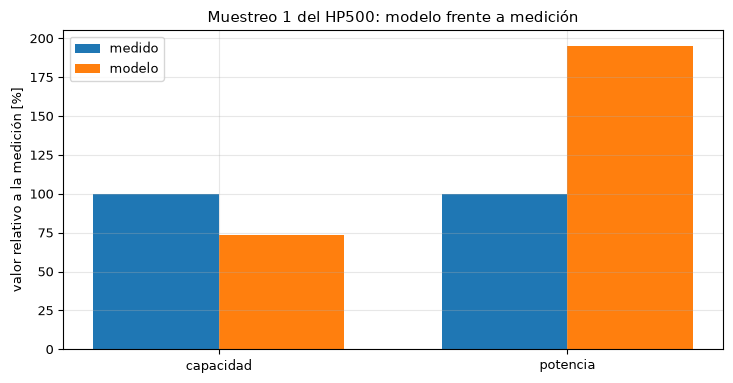

In [9]:
# Gráfico de barras de capacidad y potencia medidas frente a modeladas para el muestreo 1, cada una relativa a la medición
labels = ["capacidad", "potencia"]
measured = np.array([survey.feed_tph, survey.power_kw])
modelled = np.array([real.throughput_tph, real.power_kw])
x = np.arange(2)
fig, ax = plt.subplots()
ax.bar(x - 0.18, np.ones(2) * 100, 0.36, label="medido")
ax.bar(x + 0.18, modelled / measured * 100, 0.36, label="modelo")
ax.set_xticks(x, labels)
ax.set_ylabel("valor relativo a la medición [%]")
ax.set_title("Muestreo 1 del HP500: modelo frente a medición")
ax.legend()
fig.tight_layout()
plt.show()

La barra de capacidad del modelo es más corta que la medida y la de potencia es más alta, de modo que el modelo queda bajo el tonelaje de la planta y sobre su potencia. Un solo muestreo no prueba nada sobre un modelo, y una barra no dice si una brecha es típica; el tema 05 repite esta comparación en los diez muestreos y el tema 06 pregunta cuánto de la brecha puede afirmar con honestidad una validación con datos retenidos. Por ahora la figura solo fija el orden de magnitud: el motor está en el rango correcto en tonelaje y no lo está en potencia.

## Resultados

**Respuesta:** en el punto de referencia S01 (CSS 32 mm, carrera 30 mm, 360 rpm, una alimentación de F80 126,03 mm) el motor entrega un P80 de producto de 27,70 mm, una razón de reducción de 4,55, una capacidad de 643 t/h y una potencia de 287 kW, en régimen atorado y válido. Corrido en el muestreo 1 del HP500 (CSS 54 mm, f80 88 mm) entrega 1209 t/h frente a los 1639 t/h que alimentó la planta, 26,2 por ciento menos, y 408 kW frente a 209 kW medidos, un valor del modelo 95 por ciento sobre la planta.

Lo que muestra la primera figura: la curva del producto queda a la izquierda de la de la alimentación en todo el rango, el cruce con 80 por ciento pasó de 126 mm a 28 mm, y nada se creó ni se perdió en el camino, porque ambas curvas terminan en 100 por ciento. Lo que no muestra: los tres números de la respuesta son salidas de un modelo, no mediciones, y para S01 no hay planta con la cual compararlos, porque S01 es un punto de referencia sintético. Lo que muestra la segunda figura: frente a un muestreo real, la brecha de capacidad y la de potencia tienen signos opuestos. Un validador concluiría que un solo muestreo no separa un sesgo del ruido, y que la brecha de potencia merece su propio análisis, que dan el tema 04 y el tema 06.

## Resumen

Un punto de operación son ocho números; `evaluate` lo convierte en una distribución de tamaños del producto sobre una malla de 28 clases de raíz de dos, más capacidad y potencia, en una sola llamada. La misma llamada sirve a los casos sintéticos y a la vía calibrada del HP500. Un muestreo de planta es una evidencia de otra naturaleza que una corrida de modelo: el lector necesita los números del muestreo junto a los del modelo. El siguiente notebook de este tema repite los 27 casos horneados frente al motor vivo, y el tema 02 desarma la alimentación.

## Referencias

- Whiten, W. J. (1972), The simulation of crushing plants with models developed using multiple spline regression, Journal of the South African Institute of Mining and Metallurgy 72(10), 257-264. https://www.saimm.co.za/Conferences/Apcom72/317-Whiten.pdf
- Napier-Munn, T. J., Morrell, S., Morrison, R. D., Kojovic, T. (1996), Mineral Comminution Circuits: Their Operation and Optimisation, JKMRC. https://search.worldcat.org/title/37081193
- Rocha, B. K. N., Campos, T. M., Silva, J., Tavares, L. M. (2024), Fit-for-Purpose Model of HP500 Cone Crusher in Size Reduction of Itabirite Iron Ore, Minerals 14(9), 919. https://doi.org/10.3390/min14090919
- Rosin, P., Rammler, E. (1933), The laws governing the fineness of powdered coal, Journal of the Institute of Fuel 7, 29-36. https://cir.nii.ac.jp/crid/1572543024341127296